In [145]:
### This Script is designed to parse and aggregate Replica data so that it can be placed into Flowmap_Blue


In [144]:
STEPS COMPLETED IN THIS NOTEBOOK

- 1 Import Replica Data and Census Data
- 2 Make Centroids for census tracts.
    - These should have all census tract attributes
    - Create Longitude / Latitude Fields for the centroids
- 3 Join Replica Data to Centroids
- 4 Create sheet of origin and destination locations that matches Flowmap blue template
- 5 Review sample Flowmap Blue project to see which parts of template are necessary


TO DO
- 6 Strategize how Flows can be aggregated. Eventually this should be interactive and flexible,
    so that users can choose the times, dates, weeks etc that they are interested in mapping. 
        - Part of this might also tie into the flowmap template, which allows for multiple flow sheets. 
- 7 Make drag and drop flask app, that handles replica csvs.
    - Drop replica file into browser window
    -select days and times
    -python identifies county(ies) and parses file based on time selections
    -creates flowmap compatible sheet. 
-8 Quantify the number of intra-geo trips
        

Questions
---------
-How are census tracts named in Replica Data vs in the Census Geographies?
    -Replica Data appears to use Census GEOID column
    
-Some destination tracts are populated with the value "aggregated_low_volumes"
    -What exactly does this mean and how should it be handled?
    -Rows with this value appear to have proper GEOIDs in Origin column. 


SyntaxError: invalid syntax (<ipython-input-144-aad230150d1f>, line 1)

In [1]:
import os
import pandas as pd
import xlsxwriter
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
#Replica Data
replica_data = "/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/Alameda-County--CA-&-4-other-areas_O-D-data_Trips-ending-in-location_Tract_weekof_Jan-27--2020.csv"

#Flowmap Template
flowmap_blue = "/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/Flowmap.blue template spreadsheet.xlsx"

#California Census Tracts -  Cartographic Boundaries
census_tracts = "/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/cb_2018_06_tract_500k/cb_2018_06_tract_500k.shp"

excel_output= '/Users/calvindechicago/PycharmProjects/AltaWork/Replica_Flowmap_Blue/Script_excel_output/flowmap_blue_script_output.xlsx'


print("replica filepath is valid: ",  os.path.isfile(replica_data))
print("flowmap template filepath is valid: ", os.path.isfile(flowmap_blue))
print("census tract filepath is valid: ",  os.path.isfile(census_tracts))

replica filepath is valid:  True
flowmap template filepath is valid:  True
census tract filepath is valid:  True


In [3]:
os.path.isfile(replica_data)

True

In [45]:
# Create dataframe from Replica data
replica = pd.read_csv(replica_data)

# Create dataframes for each Flowmap template sheet
flowmap_prop = pd.read_excel(flowmap_blue,0)
flowmap_locations = pd.read_excel(flowmap_blue,1)
flowmap_flows = pd.read_excel(flowmap_blue,2)


In [5]:
# Create geodataframe from Census Tract Data
census_tracts = gpd.read_file(census_tracts)

In [6]:
# Reproject census tract data to EPSG 2227
census_tracts = census_tracts.to_crs("EPSG:2227")

In [7]:
#Dissolve census tracts by county
ct_dis = census_tracts.dissolve(by='COUNTYFP')

In [8]:
# Create county fips column
ct_dis['COUNTYFP'] = ct_dis.index

In [9]:
# Create Alameda dataframe
alam = ct_dis.loc[ct_dis['COUNTYFP'] == '001']

In [10]:
# Buffer Alameda County (900000 ft is about 170 miles)

alam_b = alam.buffer(900000, 30)
print(type(alam_b))

# Buffer function ouputs geoseries, but we want a geodataframe
# Convert buffer output to geodataframe
alam_b = gpd.GeoDataFrame(gpd.GeoSeries(alam_b))

# Set geometry column
alam_b = alam_b.rename(columns={0:'geometry'}).set_geometry('geometry')

# Set CRS
print(alam_b.crs)
alam_b.crs = 'epsg:2227'


<class 'geopandas.geoseries.GeoSeries'>
None


In [15]:
#Intersect overlay function clips geometry. This will not work because these are census tract.
#What we want is a filtered selection of any census tract that intersects with the buffered study County
#geopandas.sjoin(left_df, right_df, how='inner', op='intersects', lsuffix='left', rsuffix='right')

ctracts = gpd.sjoin(census_tracts, alam_b, how='inner', op='intersects')

In [19]:
# Create Centroids for study area census tracts
ctracts['geometry'] = ctracts.centroid




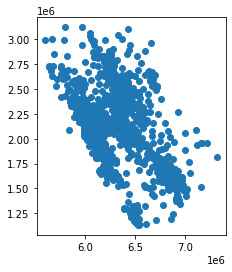

In [20]:
ctracts.plot()

In [23]:
# Project to EPSG 4326, which is compatible with Flowmap

ctracts = ctracts.to_crs("EPSG:4326")

In [27]:
# Flowmap requires a Latitude column and a longitude column.  Make Lat/Lon columns

ctracts['lon'] = ctracts.geometry.x
ctracts['lat'] = ctracts.geometry.y

In [34]:
#Make a sheet of locations for Flowmap
locations = ctracts[['GEOID', 'lat', 'lon']]

In [35]:
# Set GEOID data type. 

new_dtypes = {"GEOID": 'int64'}

locations = locations.astype(new_dtypes)

In [36]:
# Flowmap requires a column named 'id'. Create this from the GEOID column here. 
locations['id'] = locations['GEOID']

# Remove GEOID column
locations = locations[['id','lat', 'lon']]


In [37]:
#Rename Index
locations.loc[:,'name'] = locations.index


In [38]:
# Sum all 'start_hour_trips_count_avg_weekday' values for each OD pair
replica_group = replica.groupby(['origin_tract', 'destination_tract'])['start_hour_trips_count_avg_weekday'].agg(sum).reset_index(name ='count')

In [39]:
replica_agg = replica_group.sort_values(by='count', ascending = False)

In [40]:
# Remove rows with 'aggregated_low_volumns' value
replica_agg = replica_agg.loc[replica_agg['destination_tract'] != 'aggregated_low_volumes']

In [41]:
new_dtypes = {"origin_tract": 'int64',
              "destination_tract": 'int64', 
              "count": 'int64'}

replica_agg = replica_agg.astype(new_dtypes)




In [42]:
# Identify and remove intra-geo trips
replica_agg = replica_agg.loc[replica_agg['origin_tract'] != replica_agg['destination_tract']]

In [43]:
replica_agg.columns = ['origin', 'dest', 'count']

In [47]:
# Remove unwanted rows from Flowmap properties sheet. 
properties = flowmap_prop.loc[flowmap_prop['property'] != 'mapbox.accessToken']


In [200]:
# Export Flowmap Compatible dataframes to Excel. 
# The exported Excel file can be imported directly into Google Sheets, which can be used with Flowmap.blue

with pd.ExcelWriter(excel_output, mode='A') as writer:
    replica_agg.to_excel(writer, index=False, sheet_name='flows')
    locations.to_excel(writer, index=False, sheet_name='locations')
    properties.to_excel(writer, index=False, sheet_name='properties')
